In [2]:
!pip install faiss-cpu annoy hnswlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 17.5 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.5/19.5 MB 34.0 MB/s  0:00:00
  Created wheel for annoy: filename=annoy-1.17.3-cp313-cp313-linux_x86_64.whl size=520037 sha256=34abab2e9d9c4786b46783ccd9b496938ae4f3575ec267445044001ce4054646
  Stored in directory: /root/.cache/pip/wheels/fc/4e/87/f1f957e7382aa370452cff98276f51686924d5415e449800ed
  Created wheel for hnswlib: filename=hnswlib-0.8.0-cp313-cp313-linux_x86_64.whl size=2679798 sha256=c18cfed8491d00b39826c47e80d3ba98003337b1e31aa85681bd498c6dfff9b2
  Stored in directory: /root/.cache/pip/wheels/35/04/88/b31765a4b9957705e18065db4657e61fc8da54f5

In [3]:
import faiss
import hnswlib
import numpy as np
import time
from annoy import AnnoyIndex

# 1. Buat data dummy (10.000 vektor, masing-masing berdimensi 128)
np.random.seed(42)
dim = 128
n_data = 10000
n_query = 100
k = 5  # ambil 5 tetangga terdekat

data = np.random.random((n_data, dim)).astype('float32')
queries = np.random.random((n_query, dim)).astype('float32')

# ==========================================
# 2. FAISS (IndexFlatL2 - Exact Search)
# ==========================================
t0 = time.time()
faiss_index = faiss.IndexFlatL2(dim)
faiss_index.add(data)
t_build_faiss = time.time() - t0

t0 = time.time()
D_faiss, I_faiss = faiss_index.search(queries, k)
t_search_faiss = time.time() - t0

# ==========================================
# 3. ANNOY (Approximate Nearest Neighbors)
# ==========================================
t0 = time.time()
annoy_index = AnnoyIndex(dim, 'euclidean')
for i in range(n_data):
  annoy_index.add_item(i, data[i])
annoy_index.build(10)  # 10 trees
t_build_annoy = time.time() - t0

t0 = time.time()
I_annoy = []
for q in queries:
  I_annoy.append(annoy_index.get_nns_by_vector(q, k))
t_search_annoy = time.time() - t0

# ==========================================
# 4. HNSWLIB (Hierarchical Navigable Small World)
# ==========================================
t0 = time.time()
hnsw_index = hnswlib.Index(space='l2', dim=dim)
hnsw_index.init_index(max_elements=n_data, ef_construction=200, M=16)
hnsw_index.add_items(data)
hnsw_index.set_ef(50)
t_build_hnsw = time.time() - t0

t0 = time.time()
I_hnsw, D_hnsw = hnsw_index.knn_query(queries, k=k)
t_search_hnsw = time.time() - t0

# ==========================================
# 5. Ringkasan Hasil
# ==========================================
print(
    f'FAISS   -> Build: {t_build_faiss:.4f}s | Search: {t_search_faiss:.4f}s'
)
print(
    f'Annoy   -> Build: {t_build_annoy:.4f}s | Search: {t_search_annoy:.4f}s'
)
print(f'HNSWLIB -> Build: {t_build_hnsw:.4f}s | Search: {t_search_hnsw:.4f}s')
print('\nContoh hasil query pertama (ID tetangga terdekat):')
print('FAISS  :', I_faiss[0])
print('Annoy  :', I_annoy[0])
print('HNSWLIB:', I_hnsw[0])

FAISS   -> Build: 0.0132s | Search: 0.1584s
Annoy   -> Build: 1.3172s | Search: 0.0060s
HNSWLIB -> Build: 4.1657s | Search: 0.0080s

Contoh hasil query pertama (ID tetangga terdekat):
FAISS  : [8769 9385   82 5125 9571]
Annoy  : [82, 1578, 4478, 4719, 6215]
HNSWLIB: [  82 5125 4436 4195 7402]


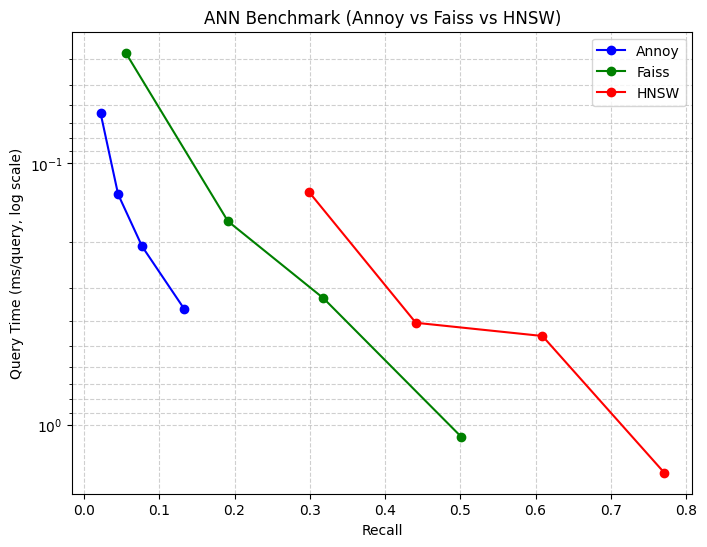

In [4]:
	import numpy as np
	import time
	import faiss
	from annoy import AnnoyIndex
	import hnswlib
	import matplotlib.pyplot as plt

	# -------------------------------
	# Random dataset
	# -------------------------------
	d = 128        # dimension
	nb = 100000    # number of database vectors
	nq = 1000      # number of queries

	np.random.seed(42)
	xb = np.random.random((nb, d)).astype('float32')
	xq = np.random.random((nq, d)).astype('float32')

	# -------------------------------
	# Ground truth with FAISS brute force
	# -------------------------------
	index_flat = faiss.IndexFlatL2(d)
	index_flat.add(xb)
	k = 10
	_, gt_idx = index_flat.search(xq, k)

	# -------------------------------
	# Recall function
	# -------------------------------
	def recall_at_k(I_pred, I_gt, k):
	    correct = 0
	    for i in range(len(I_pred)):
	        correct += len(set(I_pred[i][:k]) & set(I_gt[i][:k]))
	    return correct / (len(I_pred) * k)

	# -------------------------------
	# Annoy benchmark
	# -------------------------------
	def run_annoy(xb, xq, n_trees=10, search_k=1000, k=10):
	    f = xb.shape[1]
	    index = AnnoyIndex(f, 'euclidean')
	    for i, v in enumerate(xb):
	        index.add_item(i, v)
	    index.build(n_trees)

	    start = time.time()
	    I = [index.get_nns_by_vector(v, k, search_k=search_k) for v in xq]
	    elapsed = (time.time() - start) * 1000 / len(xq)  # ms/query
	    rec = recall_at_k(I, gt_idx, k)
	    return rec, elapsed

	# -------------------------------
	# FAISS IVF benchmark
	# -------------------------------
	def run_faiss(xb, xq, nlist=100, nprobe=10, k=10):
	    quantizer = faiss.IndexFlatL2(d)
	    index = faiss.IndexIVFFlat(quantizer, d, nlist, faiss.METRIC_L2)
	    index.train(xb)
	    index.add(xb)

	    index.nprobe = nprobe
	    start = time.time()
	    _, I = index.search(xq, k)
	    elapsed = (time.time() - start) * 1000 / len(xq)
	    rec = recall_at_k(I, gt_idx, k)
	    return rec, elapsed

	# -------------------------------
	# HNSW benchmark
	# -------------------------------
	def run_hnsw(xb, xq, ef=100, M=16, k=10):
	    num_elements = xb.shape[0]
	    p = hnswlib.Index(space='l2', dim=d)
	    p.init_index(max_elements=num_elements, ef_construction=200, M=M)
	    p.add_items(xb)
	    p.set_ef(ef)

	    start = time.time()
	    I, _ = p.knn_query(xq, k)
	    elapsed = (time.time() - start) * 1000 / len(xq)
	    rec = recall_at_k(I, gt_idx, k)
	    return rec, elapsed

	# -------------------------------
	# Run benchmark with several parameters
	# -------------------------------
	results = {"Annoy": [], "Faiss": [], "HNSW": []}

	# Annoy
	for sk in [200, 500, 1000, 2000]:
	    rec, t = run_annoy(xb, xq, n_trees=10, search_k=sk)
	    results["Annoy"].append((rec, t))

	# FAISS
	for npb in [1, 5, 10, 20]:
	    rec, t = run_faiss(xb, xq, nlist=100, nprobe=npb)
	    results["Faiss"].append((rec, t))

	# HNSW
	for ef in [50, 100, 200, 400]:
	    rec, t = run_hnsw(xb, xq, ef=ef)
	    results["HNSW"].append((rec, t))

	# -------------------------------
	# Visualize the trade-off
	# -------------------------------
	plt.figure(figsize=(8,6))
	for label, color in zip(results.keys(), ["blue","green","red"]):
	    recall, qtime = zip(*results[label])
	    plt.plot(recall, qtime, marker="o", label=label, color=color)

	plt.xlabel("Recall")
	plt.ylabel("Query Time (ms/query, log scale)")
	plt.yscale("log")
	plt.gca().invert_yaxis()  # invert Y, the more to the right the lower
	plt.title("ANN Benchmark (Annoy vs Faiss vs HNSW)")
	plt.legend()
	plt.grid(True, which="both", ls="--", alpha=0.6)
	plt.show()